Dataset Shape: (10000, 14)

Columns after cleaning:
 Index(['Year', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure',
       'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember',
       'EstimatedSalary', 'Exited'],
      dtype='object')

Data Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CreditScore      10000 non-null  int64  
 2   Geography        10000 non-null  object 
 3   Gender           10000 non-null  object 
 4   Age              10000 non-null  int64  
 5   Tenure           10000 non-null  int64  
 6   Balance          10000 non-null  float64
 7   NumOfProducts    10000 non-null  int64  
 8   HasCrCard        10000 non-null  int64  
 9   IsActiveMember   10000 non-null  int64  
 10  EstimatedSalary  10000 non-null  float64
 11  Exited           10000 non-n

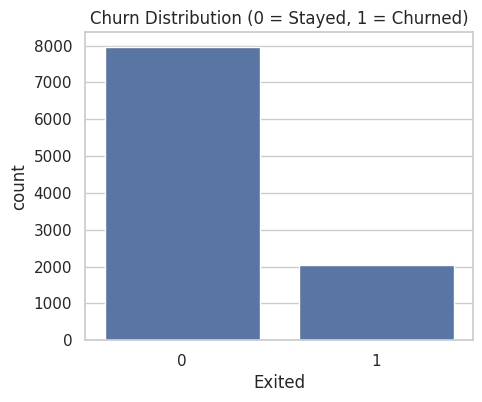

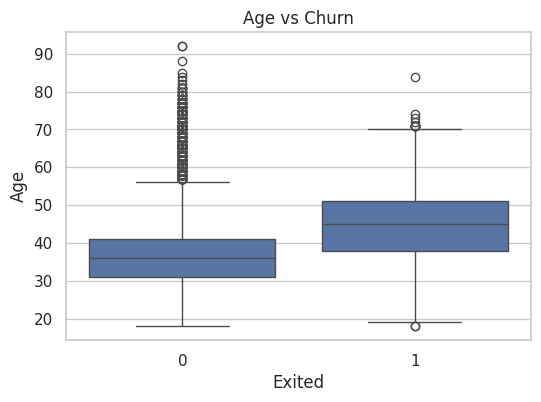

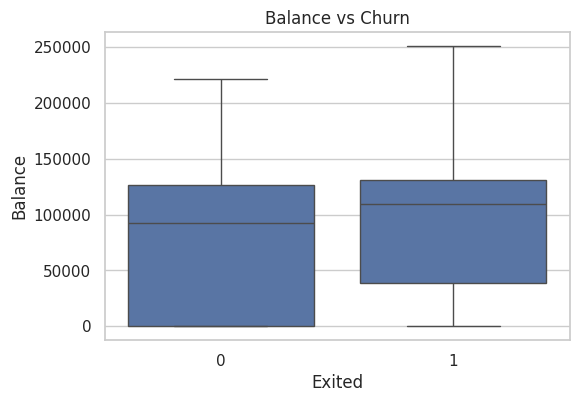

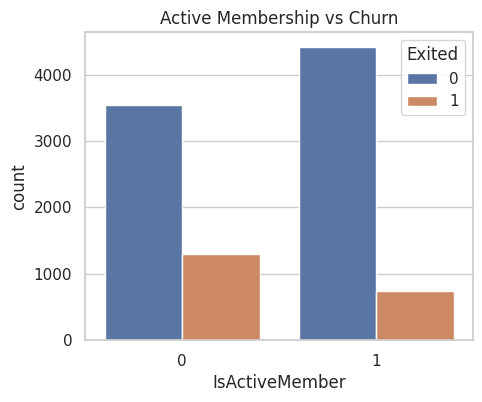

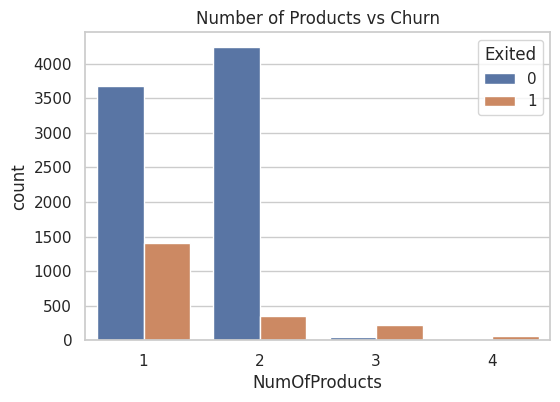

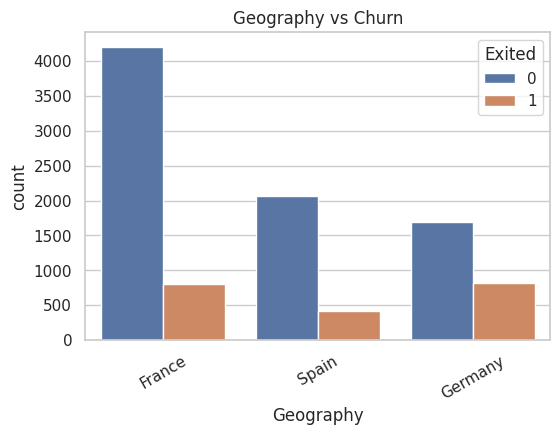

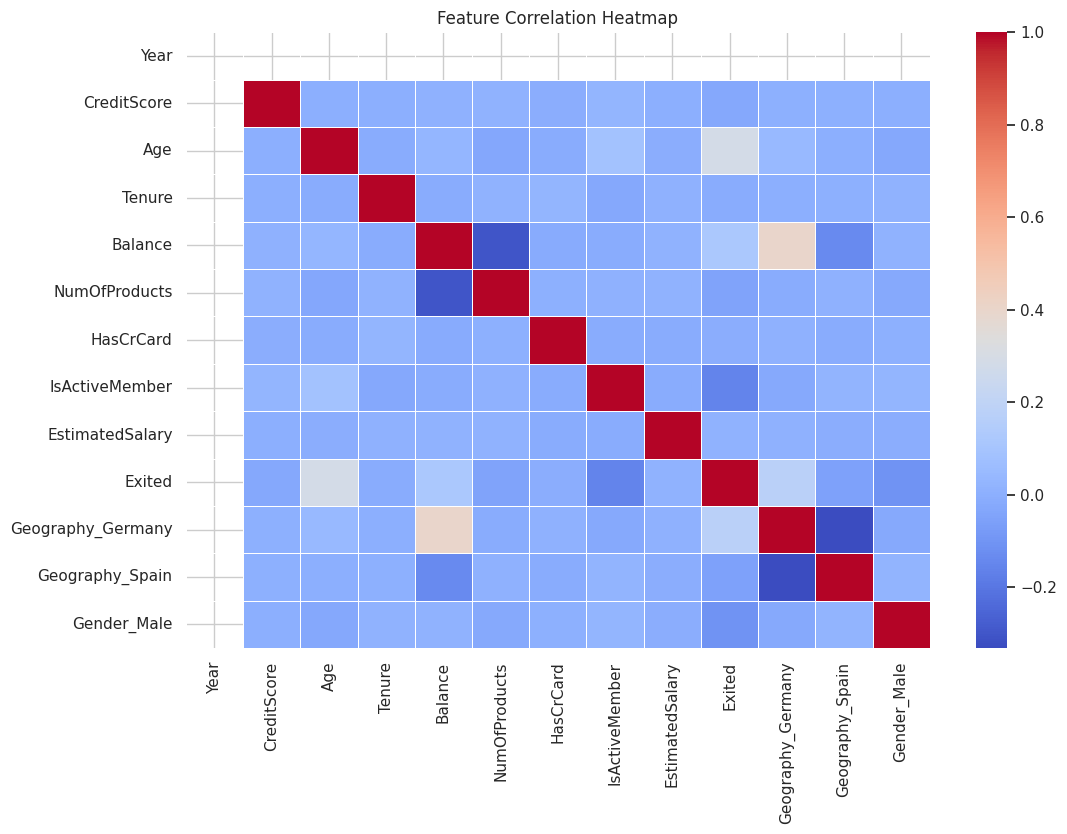

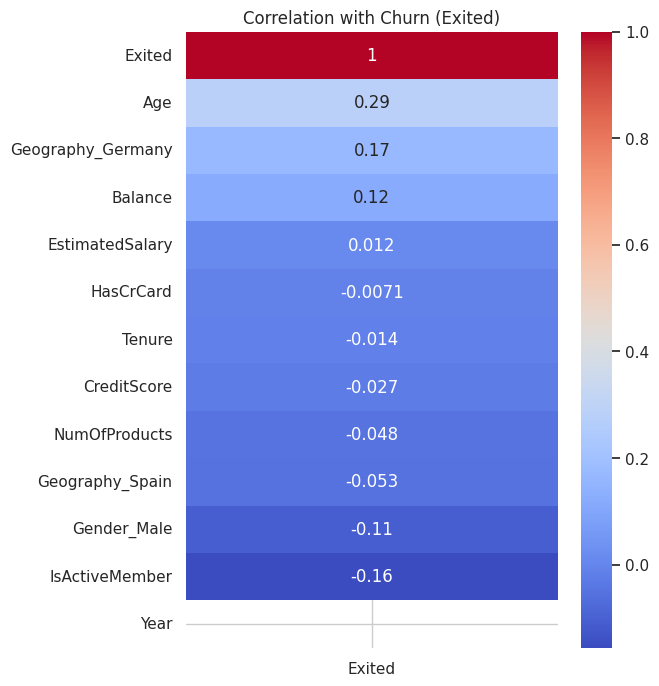


===== KEY INSIGHTS =====

1. Older customers tend to churn more.
2. Customers with fewer products are more likely to churn.
3. Inactive members show higher churn rates.
4. Balance and geography also influence churn behavior.


In [2]:
# =========================
# CUSTOMER CHURN ANALYSIS (EDA)
# =========================

# -------------------------
# IMPORT LIBRARIES
# -------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# -------------------------
# LOAD DATA
# -------------------------
df = pd.read_csv("European_Bank.csv.csv")

print("Dataset Shape:", df.shape)
df.head()

# -------------------------
# DATA CLEANING
# -------------------------
# Drop unnecessary columns
df = df.drop(columns=[col for col in ['CustomerId', 'Surname'] if col in df.columns])

print("\nColumns after cleaning:\n", df.columns)

# -------------------------
# BASIC INFO
# -------------------------
print("\nData Info:\n")
df.info()

print("\nMissing Values:\n")
print(df.isnull().sum())

# -------------------------
# ENCODING (for analysis + correlation)
# -------------------------
df_encoded = pd.get_dummies(df, drop_first=True)

# -------------------------
# TARGET DISTRIBUTION
# -------------------------
plt.figure(figsize=(5,4))
sns.countplot(x='Exited', data=df)
plt.title("Churn Distribution (0 = Stayed, 1 = Churned)")
plt.show()

# -------------------------
# AGE vs CHURN
# -------------------------
plt.figure(figsize=(6,4))
sns.boxplot(x='Exited', y='Age', data=df)
plt.title("Age vs Churn")
plt.show()

# -------------------------
# BALANCE vs CHURN
# -------------------------
plt.figure(figsize=(6,4))
sns.boxplot(x='Exited', y='Balance', data=df)
plt.title("Balance vs Churn")
plt.show()

# -------------------------
# ACTIVE MEMBER vs CHURN
# -------------------------
plt.figure(figsize=(5,4))
sns.countplot(x='IsActiveMember', hue='Exited', data=df)
plt.title("Active Membership vs Churn")
plt.show()

# -------------------------
# NUMBER OF PRODUCTS vs CHURN
# -------------------------
plt.figure(figsize=(6,4))
sns.countplot(x='NumOfProducts', hue='Exited', data=df)
plt.title("Number of Products vs Churn")
plt.show()

# -------------------------
# GEOGRAPHY vs CHURN
# -------------------------
plt.figure(figsize=(6,4))
sns.countplot(x='Geography', hue='Exited', data=df)
plt.title("Geography vs Churn")
plt.xticks(rotation=30)
plt.show()

# -------------------------
# CORRELATION HEATMAP (FULL)
# -------------------------
plt.figure(figsize=(12,8))
corr = df_encoded.corr()

sns.heatmap(corr, cmap='coolwarm', linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

# -------------------------
# CORRELATION WITH TARGET (BEST VISUAL)
# -------------------------
corr_target = corr['Exited'].sort_values(ascending=False)

plt.figure(figsize=(6,8))
sns.heatmap(corr_target.to_frame(), annot=True, cmap='coolwarm')
plt.title("Correlation with Churn (Exited)")
plt.show()

# -------------------------
# SUMMARY INSIGHTS PRINT
# -------------------------
print("\n===== KEY INSIGHTS =====\n")

print("1. Older customers tend to churn more.")
print("2. Customers with fewer products are more likely to churn.")
print("3. Inactive members show higher churn rates.")
print("4. Balance and geography also influence churn behavior.")